In [1]:
import pandas as pd
import matplotlib.pyplot as plt

df = pd.read_csv("../../datasets/heart.csv")

numerical_columns = df.select_dtypes(include="number").columns.tolist()

print("Numerical columns:", numerical_columns)
print("Dataset shape:", df.shape)

Numerical columns: ['age', 'sex', 'cp', 'trestbps', 'chol', 'fbs', 'restecg', 'thalach', 'exang', 'oldpeak', 'slope', 'ca', 'thal', 'target']
Dataset shape: (1025, 14)


In [2]:
def manual_percentile(values, percentile):
    values = sorted(float(x) for x in values if pd.notna(x))

    if len(values) == 0:
        return None

    position = (len(values) - 1) * percentile / 100
    lower = int(position)
    upper = min(lower + 1, len(values) - 1)
    fraction = position - lower

    return values[lower] + fraction * (
        values[upper] - values[lower]
    )


def manual_boxplot_stats(values):
    values = [float(x) for x in values if pd.notna(x)]

    if len(values) == 0:
        return None

    q1 = manual_percentile(values, 25)
    median = manual_percentile(values, 50)
    q3 = manual_percentile(values, 75)

    iqr = q3 - q1
    lower_fence = q1 - 1.5 * iqr
    upper_fence = q3 + 1.5 * iqr

    outliers = [
        x for x in values
        if x < lower_fence or x > upper_fence
    ]

    inliers = [
        x for x in values
        if lower_fence <= x <= upper_fence
    ]

    return {
        "q1": q1,
        "median": median,
        "q3": q3,
        "iqr": iqr,
        "lower_fence": lower_fence,
        "upper_fence": upper_fence,
        "lower_whisker": min(inliers) if inliers else None,
        "upper_whisker": max(inliers) if inliers else None,
        "outliers": outliers
    }

In [3]:
boxplot_results = {}

for col in numerical_columns:
    stats = manual_boxplot_stats(df[col].tolist())

    if stats is None:
        print(f"{col}: No valid values")
        continue

    boxplot_results[col] = stats

    print(f"\nColumn: {col}")
    print("Q1:", round(stats["q1"], 2))
    print("Median:", round(stats["median"], 2))
    print("Q3:", round(stats["q3"], 2))
    print("IQR:", round(stats["iqr"], 2))
    print("Lower fence:", round(stats["lower_fence"], 2))
    print("Upper fence:", round(stats["upper_fence"], 2))
    print("Lower whisker:", stats["lower_whisker"])
    print("Upper whisker:", stats["upper_whisker"])
    print("Outliers detected:", len(stats["outliers"]))


Column: age
Q1: 48.0
Median: 56.0
Q3: 61.0
IQR: 13.0
Lower fence: 28.5
Upper fence: 80.5
Lower whisker: 29.0
Upper whisker: 77.0
Outliers detected: 0

Column: sex
Q1: 0.0
Median: 1.0
Q3: 1.0
IQR: 1.0
Lower fence: -1.5
Upper fence: 2.5
Lower whisker: 0.0
Upper whisker: 1.0
Outliers detected: 0

Column: cp
Q1: 0.0
Median: 1.0
Q3: 2.0
IQR: 2.0
Lower fence: -3.0
Upper fence: 5.0
Lower whisker: 0.0
Upper whisker: 3.0
Outliers detected: 0

Column: trestbps
Q1: 120.0
Median: 130.0
Q3: 140.0
IQR: 20.0
Lower fence: 90.0
Upper fence: 170.0
Lower whisker: 94.0
Upper whisker: 170.0
Outliers detected: 30

Column: chol
Q1: 211.0
Median: 240.0
Q3: 275.0
IQR: 64.0
Lower fence: 115.0
Upper fence: 371.0
Lower whisker: 126.0
Upper whisker: 360.0
Outliers detected: 16

Column: fbs
Q1: 0.0
Median: 0.0
Q3: 0.0
IQR: 0.0
Lower fence: 0.0
Upper fence: 0.0
Lower whisker: 0.0
Upper whisker: 0.0
Outliers detected: 153

Column: restecg
Q1: 0.0
Median: 1.0
Q3: 1.0
IQR: 1.0
Lower fence: -1.5
Upper fence: 2.5
Lower 

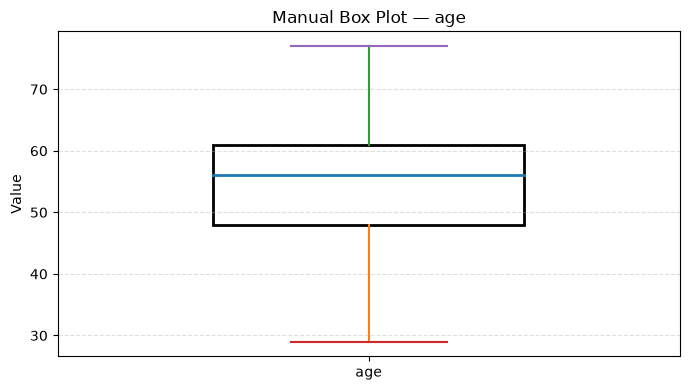

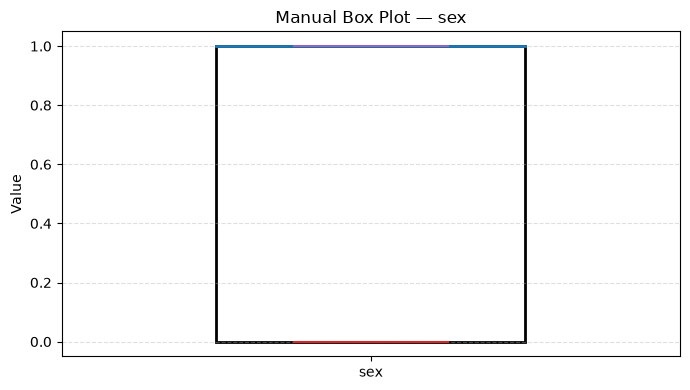

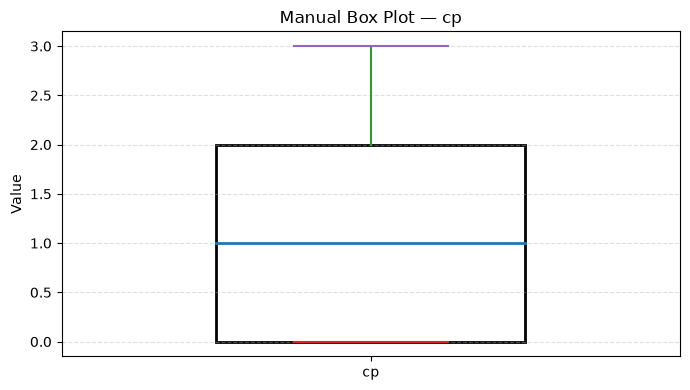

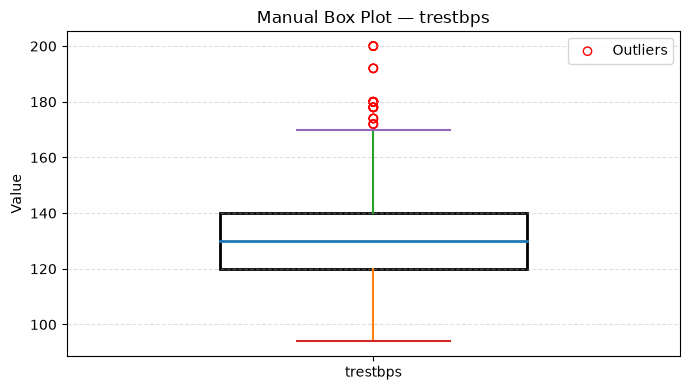

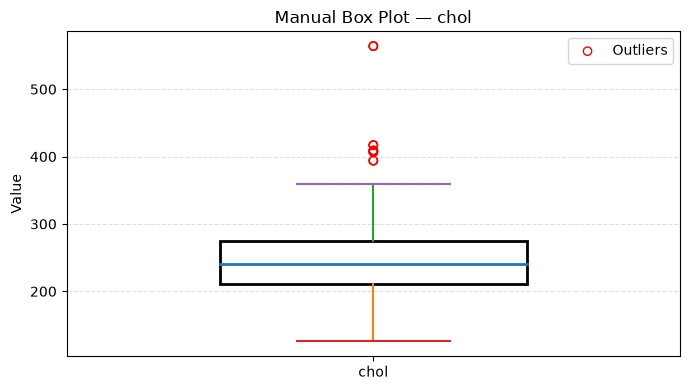

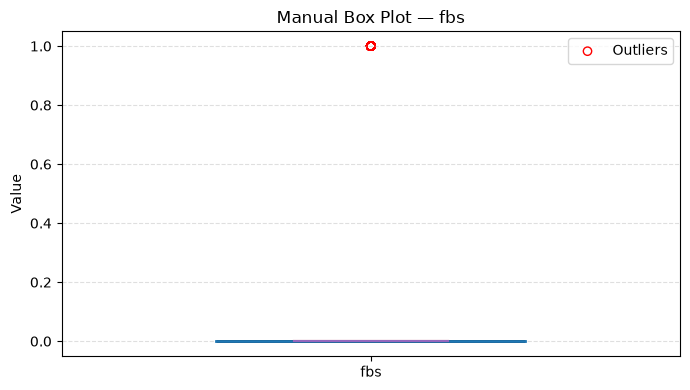

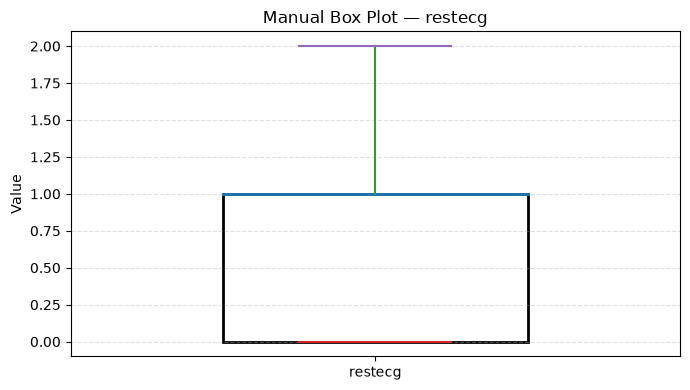

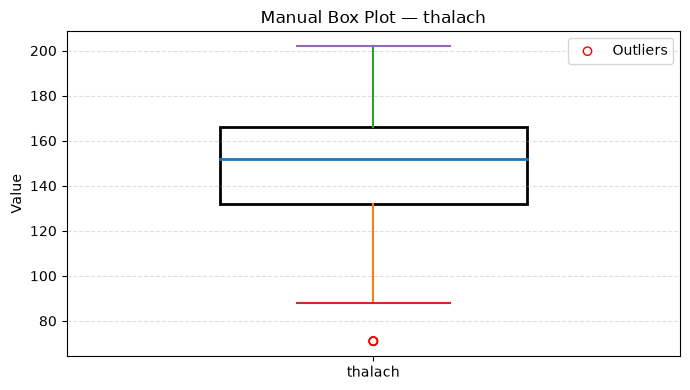

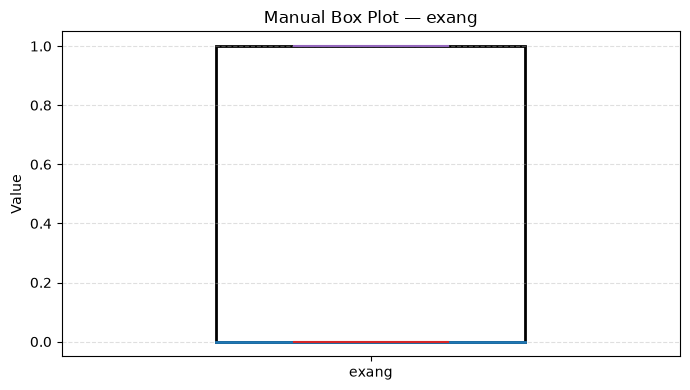

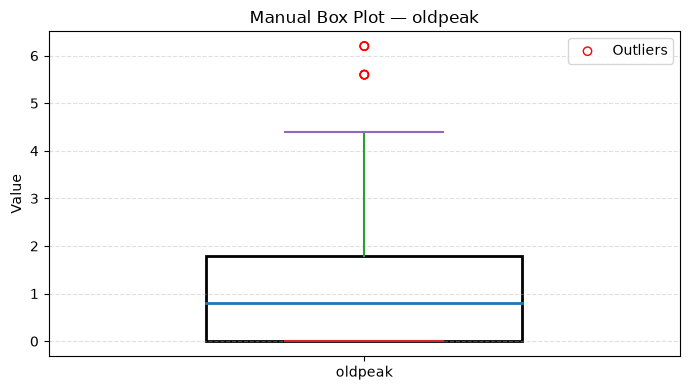

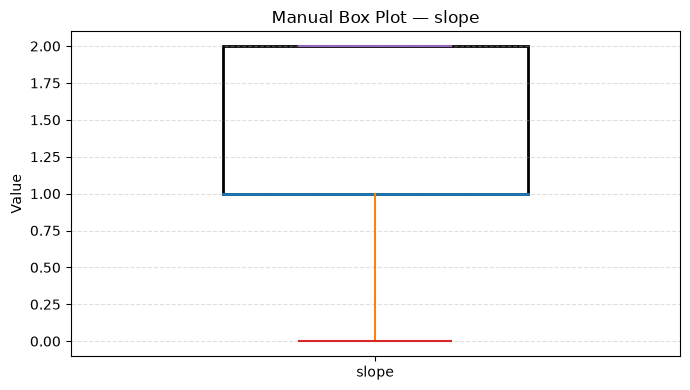

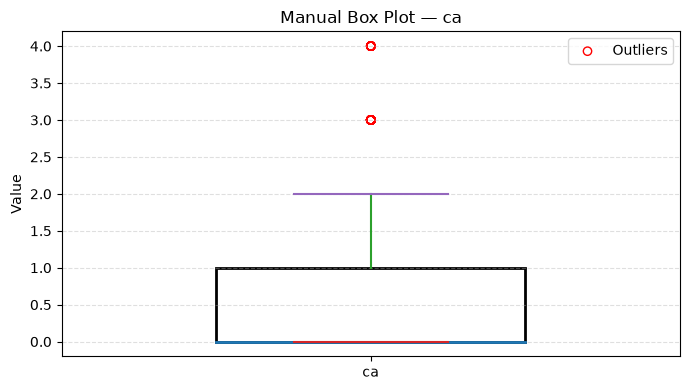

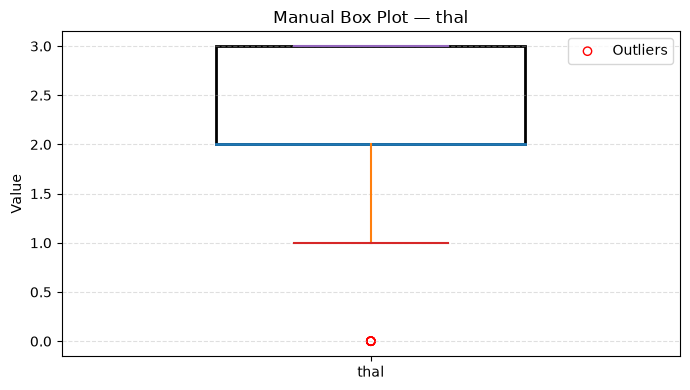

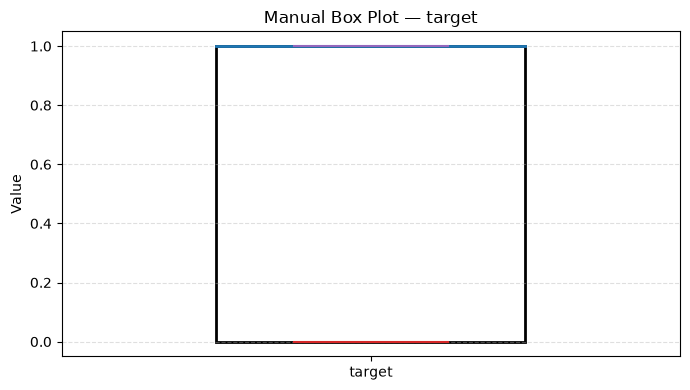

In [4]:
for col in numerical_columns:
    stats = boxplot_results.get(col)

    if stats is None:
        continue

    q1 = stats["q1"]
    median = stats["median"]
    q3 = stats["q3"]
    lower_whisker = stats["lower_whisker"]
    upper_whisker = stats["upper_whisker"]
    outliers = stats["outliers"]

    if lower_whisker is None or upper_whisker is None:
        continue

    fig, ax = plt.subplots(figsize=(7, 4))

    # Draw the box from Q1 to Q3
    ax.add_patch(
        plt.Rectangle(
            (0.7, q1),
            0.6,
            q3 - q1,
            fill=False,
            edgecolor="black",
            linewidth=2
        )
    )

    # Median line
    ax.plot([0.7, 1.3], [median, median], linewidth=2)

    # Whiskers
    ax.plot([1, 1], [lower_whisker, q1], linewidth=1.5)
    ax.plot([1, 1], [q3, upper_whisker], linewidth=1.5)

    # Whisker caps
    ax.plot([0.85, 1.15], [lower_whisker, lower_whisker])
    ax.plot([0.85, 1.15], [upper_whisker, upper_whisker])

    # Draw outlier points
    if outliers:
        ax.scatter(
            [1] * len(outliers),
            outliers,
            marker="o",
            facecolors="none",
            edgecolors="red",
            label="Outliers"
        )
        ax.legend()

    ax.set_xlim(0.4, 1.6)
    ax.set_xticks([1])
    ax.set_xticklabels([col])
    ax.set_ylabel("Value")
    ax.set_title(f"Manual Box Plot — {col}")
    ax.grid(axis="y", linestyle="--", alpha=0.4)

    plt.tight_layout()
    plt.show()

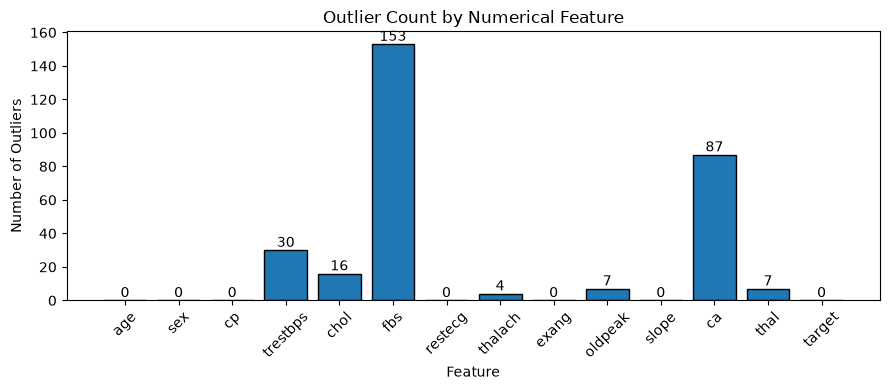

In [5]:
columns = list(boxplot_results.keys())
outlier_counts = [
    len(boxplot_results[col]["outliers"])
    for col in columns
]

plt.figure(figsize=(9, 4))

bars = plt.bar(columns, outlier_counts, edgecolor="black")

plt.title("Outlier Count by Numerical Feature")
plt.xlabel("Feature")
plt.ylabel("Number of Outliers")
plt.xticks(rotation=45)

for bar in bars:
    height = bar.get_height()
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        height,
        str(int(height)),
        ha="center",
        va="bottom"
    )

plt.tight_layout()
plt.show()

# Task 12: Manual Box Plot and Outlier Detection

## Objective
To identify outliers by manually calculating quartiles, the interquartile range (IQR), and fences, and then visualize the results using raw Matplotlib drawing functions.

## Methodology
1. Loaded the Heart Disease dataset and selected numerical columns.
2. Implemented percentile calculations manually.
3. Calculated Q1, median, Q3, and IQR for each feature.
4. Calculated lower and upper fences using 1.5 × IQR.
5. Identified observations outside the fences as potential outliers.
6. Drew box plots manually using Matplotlib shapes, lines, and scatter points.
7. Compared outlier counts across numerical features.

## Conclusion
Manual quartile and fence calculations were used to identify potential outliers. The resulting visualizations show the median, interquartile range, whiskers, and outlying observations. Statistical outliers are not necessarily errors and should be evaluated before removal.
